# Simulated CCC: compare predictions with directed ground truth

Fifteen RNA/ATAC datasets combine three spatial scenarios and five seeds. Each contains 2,000 observations and 25 simulated LR pairs. This tutorial displays CCC spatial comparisons from saved results for seed 11.

Training is commented out by default. **Run All** uses saved CellSTIC results and recomputes the analyses below. Figures and tables are saved alongside the existing model results under `DATA / "cellstic"`. Run All does not train or modify the saved model.

## 1. Set up the dataset

Start Jupyter from this repository. Use the environment in `environment.yml` and supply the assembled inputs and saved results at the paths below.

In [1]:
from pathlib import Path
import sys
import json
import anndata as ad
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, SVG, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pipeline/cellstic.py").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from pipeline.analysis import Analysis
from utils.analysis.result_io import load_result, lr_matrices, channel_keys
from utils.analysis import dataset_analysis as da
%matplotlib inline
plt.style.use("default")
plt.rcParams.update({"font.size": 10, "figure.dpi": 110})

/home/wangshuai/anaconda3/envs/spaGem/lib/python3.8/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
DATA = ROOT / "paper/data/ccc_sim"
SCENARIOS = ["domains", "gradients", "heterogeneous"]
SEEDS = [11, 23, 37, 51, 73]
SAMPLES = [f"{scenario}_{seed}" for scenario in SCENARIOS for seed in SEEDS]
RUN_ROOT = DATA / "cellstic"
OUTPUT = DATA / "cellstic"
OUTPUT.mkdir(parents=True, exist_ok=True)

## 2. Train the 15 simulations (optional)

Uncomment both cells to train every scenario and seed. The simulation benchmark applies a declared sender/receiver state prior after prediction and recomputes the ancestor scores. Its measured performance is therefore conditional on those known state constraints. Reruns use the design embedded in the assembled inputs.

In [3]:
# from dataclasses import replace
# from model.train import get_cellstic_config
# from pipeline.cellstic import run_cellstic
# from utils.analysis.simulation_analysis import constrain_simulated_result
# base = get_cellstic_config("scmultisim")
# config = replace(base, train=replace(base.train, feat=replace(base.train.feat, n_clusters=10)), seed=42)

In [4]:
# for sample in SAMPLES:
#     inputs = [ad.read_h5ad(DATA / "h5ad" / sample / f"{name}.h5ad") for name in ["rna", "atac"]]
#     lr_map = {name: list(values) for name, values in inputs[0].uns["ligand_receptor_map"].items()}
#     trained = run_cellstic(inputs, config, modality_types=["rna", "atac"],
#                           ligand_receptor_map=lr_map, output_path=RUN_ROOT / sample)
#     constrain_simulated_result(trained)
#     trained.write_h5ad(RUN_ROOT / sample / "out/out.h5ad", compression="gzip")


## 3. Compare CCC spatial patterns

The three columns show domains, gradients and heterogeneous tissue for seed 11.
The top row counts true incoming edges; the bottom row sums predicted incoming
scores at threshold 0.5. The saved results use the `sparse_within_pair_on_off_v1`
design and the declared sender/receiver state prior. Each row uses one shared
color scale across scenarios.

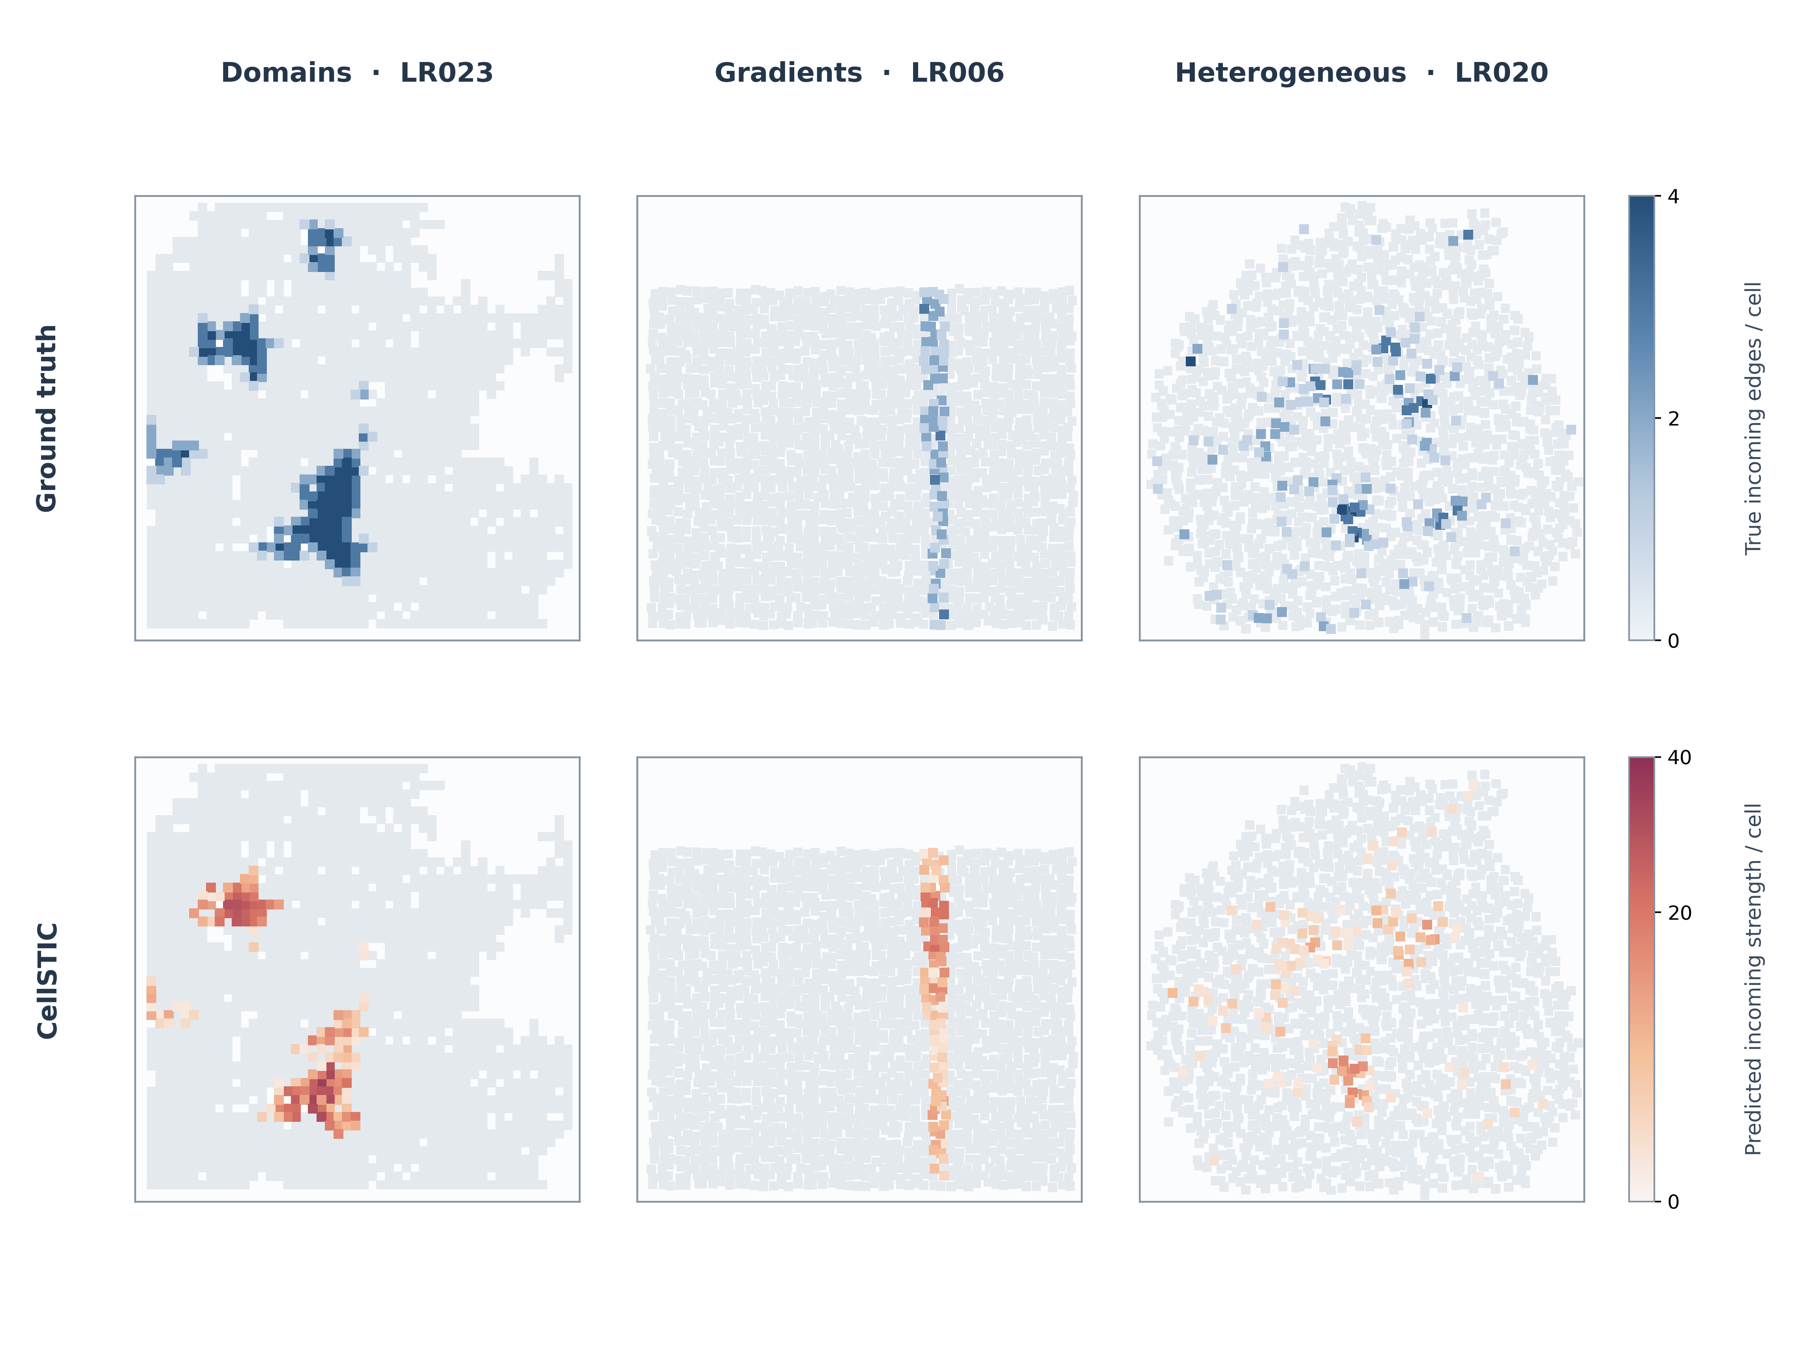

In [5]:
from utils.analysis.simulation_visualization import ccc_maps
PAIR_IDS = {"domains": "LR023", "gradients": "LR006", "heterogeneous": "LR020"}
_ = ccc_maps(RUN_ROOT, PAIR_IDS, OUTPUT / "ccc", seed=11, threshold=0.5)